# 08d Shift-aware classical models

If a product's level shifted, maybe a model forecasts better if it forgets what came before. Here we test that idea
on SARIMA, using only shifts the detector had found before each origin. SARIMA gets two versions on the
150-product sample: retrained from the shift, or kept on the full window with a regressor that marks the shift. Each
comes with a placebo: products without a shift get an equally short, random training window. If the placebo helps
as much, the shift itself was not the reason. 09 runs the same test for the best time-series model on all 726
products.

## Load

In [1]:
import os, sys, time, warnings
sys.path.append("../src")
os.environ["PYTHONPATH"] = os.path.abspath("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ast import literal_eval
from joblib import Parallel, delayed
from scipy import stats

from config import (ROOT, INTERIM, PROCESSED, TABLES, FIGS, ORIGINS, EVAL_ORIGINS, FIT_DAYS, HORIZON, SEED,
                    PRACTICAL_SHARE, FIG_STYLE)
import classical
from forecasting import local_forecasts, is_intermittent
from metrics import paired_test, holm_adjust
from evaluation import mase_scales

RERUN = False
plt.rcParams.update(FIG_STYLE)
written = []

long_df = pd.concat([pd.read_csv(INTERIM / f"{c}_candidates.csv", parse_dates=["date"])
                     for c in ["foods", "hobbies", "household"]], ignore_index=True)
long_df = long_df.sort_values(["item_id", "date"]).reset_index(drop=True)
long_df["category"] = long_df["item_id"].str.split("_").str[0]
daily = {i: g[["date", "sales"]].reset_index(drop=True) for i, g in long_df.groupby("item_id")}
windows = pd.read_csv(PROCESSED / "breaks_by_origin.csv",
                      parse_dates=["origin", "first_date", "last_change_week", "last_alarm_week", "adaptive_start", "placebo_start"])
scales = mase_scales(daily, ORIGINS)
print(f"{len(daily)} products; item-origins with a shift at a scored origin: "
      f"{int(windows[windows['origin'].isin(EVAL_ORIGINS)]['has_break'].sum())}")

726 products; item-origins with a shift at a scored origin: 2869


## The retraining windows

For a product with a shift before the origin, a retrained model trains only from the latest estimated change week
(at least 56 days). For a product without one, the placebo trains from a random date whose distance to the origin is
drawn from the real retraining windows at the same origin. Here we also make the seasonal naive versions on those
windows, which 09 uses. This is read from disk after the first run.

In [2]:
path = PROCESSED / "local_variant_forecasts.parquet"
intermittent = {item: is_intermittent(d.loc[d["date"] <= ORIGINS[0], "sales"]) for item, d in daily.items()}
if RERUN or not path.exists():
    starts = {}
    for r in windows.itertuples():
        starts.setdefault(r.item_id, {})[r.origin] = {
            "adaptive": None if pd.isna(r.adaptive_start) else r.adaptive_start,
            "placebo": None if pd.isna(r.placebo_start) else r.placebo_start}
    t0 = time.time()
    res = Parallel(n_jobs=-1, batch_size=4)(
        delayed(local_forecasts)(item, d["date"], d["sales"], ORIGINS, starts[item])
        for item, d in daily.items())
    pd.DataFrame([r for rows in res for r in rows]).to_parquet(path, index=False)
    print(f"fitted in {(time.time() - t0) / 60:.1f} min")
variants = pd.read_parquet(path)
written.append(path)
static_local = pd.read_parquet(PROCESSED / "local_static_forecasts.parquet")
print(f"{len(variants):,} rows:", variants.groupby(["model", "variant"]).size().to_dict())

## SARIMA, retrained or with a shift marker

Both versions keep each product's SARIMA order from 07a and are refitted at every origin.

The restart version trains only from the latest change week, and never on more than the last 730 days. When the
change week is older than that window, restart is simply the static model. The dummy version keeps the full
window and adds a regressor that is 0 before the change week and 1 after it (and 1 over the 28 forecast days), so
SARIMA can move its level without throwing data away. When the change week is before the window, that regressor
would be constant, so again the model is the static one. The placebo trains products without a shift from the
same random start as above, capped the same way.

The rule for "helps" is the one we used for LightGBM: per product, the mean MASE change over its shift origins; a
version helps if the Holm-corrected Wilcoxon p (restart and dummy together) is below 0.05, the median change is below
0, and the gain is at least 1% of the median static SARIMA MASE.

In [4]:
sample = pd.read_csv(TABLES / "classical_sample_items.csv")
orders = pd.read_csv(TABLES / "classical_orders.csv").set_index("series")
breaks = windows[windows["item_id"].isin(sample["item_id"]) & windows["origin"].isin(EVAL_ORIGINS)]
scores = pd.read_csv(TABLES / "classical_metrics_item_origin.csv", parse_dates=["origin"])
static = scores[scores["model"] == "sarima"][["item_id", "origin", "mase"]].rename(columns={"mase": "static"})
hc = pd.read_csv(TABLES / "hc_by_origin.csv", parse_dates=["origin"])[["item_id", "origin", "high_confidence"]]
sdaily = {i: d for i, d in daily.items() if i in set(sample["item_id"])}

def windowed(d, origin, start=None):
    """Data up to the origin, from `start` if given, never more than the last 730 days."""
    n = d["date"].searchsorted(origin, side="right")
    lo = max(0, n - FIT_DAYS)
    if start is not None and not pd.isna(start):
        lo = max(lo, d["date"].searchsorted(start))
    return d.iloc[lo:n]

def item_variants(item, d, rows, order, sorder):
    out = []
    for r in rows.itertuples():
        full = windowed(d, r.origin)
        if r.has_break:
            w = windowed(d, r.origin, r.adaptive_start)
            jobs = [("restart", w, None)]
            dummy = (full["date"] >= r.last_change_week).astype(float).to_numpy()
            jobs.append(("dummy", full, dummy))
        elif not pd.isna(r.placebo_start):
            jobs = [("placebo", windowed(d, r.origin, r.placebo_start), None)]
        else:
            jobs = []
        for variant, w, x in jobs:
            same = (len(w) == len(full)) if x is None else (x.min() == x.max())
            row = {"item_id": item, "origin": r.origin, "variant": variant, "window_days": len(w), "same_as_static": same}
            if not same:
                fc, ok, fb = classical.sarima_forecast(w["sales"].to_numpy(float), order, sorder, HORIZON,
                                                       exog=x, exog_future=None if x is None else np.ones(HORIZON))
                row.update(forecast=list(fc), converged=ok, fallback=fb)
            out.append(row)
    return out

res = Parallel(n_jobs=8)(delayed(item_variants)(i, sdaily[i], breaks[breaks["item_id"] == i],
                                                literal_eval(orders.loc[i, "sarima_order"]), literal_eval(orders.loc[i, "sarima_sorder"]))
                         for i in sample["item_id"])
var = pd.DataFrame([r for rows in res for r in rows])
var.groupby("variant").agg(item_origins=("item_id", "size"), items=("item_id", "nunique"), same_as_static=("same_as_static", "mean")).round(3)

,item_origins,items,same_as_static
variant,,,
dummy,449,75,0.437
placebo,431,76,0.411
restart,449,75,0.437


In [5]:
# score: a version that equals static gets the static score; the others are scored on their 28 test days
act = long_df.set_index(["item_id", "date"])["sales"]
sc = scales.set_index(["item_id", "origin"])["mase_scale"]
rows = []
for r in var.itertuples():
    if r.same_as_static:
        mase = np.nan
    else:
        days = pd.date_range(r.origin + pd.Timedelta(days=1), periods=HORIZON)
        a = act.loc[[(r.item_id, d) for d in days]].to_numpy()
        mase = np.mean(np.abs(a - np.asarray(r.forecast))) / sc[(r.item_id, r.origin)]
    rows.append({"item_id": r.item_id, "origin": r.origin, "variant": r.variant, "mase_variant": mase,
                 "same_as_static": r.same_as_static, "fallback": getattr(r, "fallback", False) is True,
                 "window_days": r.window_days})
sv = pd.DataFrame(rows).merge(static, on=["item_id", "origin"]).merge(hc, on=["item_id", "origin"], how="left")
sv["mase_variant"] = sv["mase_variant"].fillna(sv["static"])
sv["diff"] = sv["mase_variant"] - sv["static"]
sv["high_confidence"] = sv["high_confidence"].fillna(False).astype(bool)
sv.to_csv(TABLES / "shift_aware_item_origin.csv", index=False)
written.append(TABLES / "shift_aware_item_origin.csv")

def per_item(d):
    return d.groupby("item_id").agg(diff=("diff", "mean"), static=("static", "mean"))

out = []
for group, mask in [("all break item-origins", sv["variant"].isin(["restart", "dummy"])),
                    ("high-confidence breaks", sv["variant"].isin(["restart", "dummy"]) & sv["high_confidence"]),
                    ("only where the variant differs", sv["variant"].isin(["restart", "dummy"]) & ~sv["same_as_static"])]:
    block = []
    for v in ["restart", "dummy"]:
        p = per_item(sv[mask & (sv["variant"] == v)])
        r = {"group": group, "variant": v, **paired_test(p["diff"], seed=SEED), "median_static_mase": p["static"].median()}
        r["practical_threshold"] = PRACTICAL_SHARE * r["median_static_mase"]
        block.append(r)
    for r, ph in zip(block, holm_adjust([b["p_value"] for b in block])):
        r["p_holm"] = ph
        r["helps"] = bool(r["n"] >= 20 and ph < 0.05 and r["median_diff"] < 0 and abs(r["median_diff"]) >= r["practical_threshold"])
    out += block
pl = per_item(sv[sv["variant"] == "placebo"])
out.append({"group": "placebo (no-break item-origins)", "variant": "placebo", **paired_test(pl["diff"], seed=SEED),
            "median_static_mase": pl["static"].median(), "helps": None})
tests = pd.DataFrame(out)
tests.to_csv(TABLES / "shift_aware_tests.csv", index=False)
written.append(TABLES / "shift_aware_tests.csv")
helps_any = bool(tests[tests["group"] == "all break item-origins"]["helps"].any())
tests[["group", "variant", "n", "median_diff", "ci_low", "ci_high", "share_improved", "p_value", "p_holm", "helps"]].round(4)

,group,variant,n,median_diff,ci_low,ci_high,share_improved,p_value,p_holm,helps
0,all break item-origins,restart,75,0.0000,0.0000,0.0015,0.1867,0.0013,0.0026,False
1,all break item-origins,dummy,75,0.0000,0.0000,0.0001,0.2267,0.0287,0.0287,False
2,high-confidence breaks,restart,33,0.0000,0.0000,0.0107,0.2424,0.0301,0.0602,False
3,high-confidence breaks,dummy,33,0.0000,0.0000,0.0012,0.2121,0.0605,0.0605,False
4,only where the variant differs,restart,47,0.0062,0.0015,0.0107,0.2979,0.0009,0.0017,False
5,only where the variant differs,dummy,47,0.0010,-0.0003,0.0058,0.3617,0.0210,0.0210,False
6,placebo (no-break item-origins),placebo,76,0.0025,0.0000,0.0072,0.3816,0.0055,NaN,None


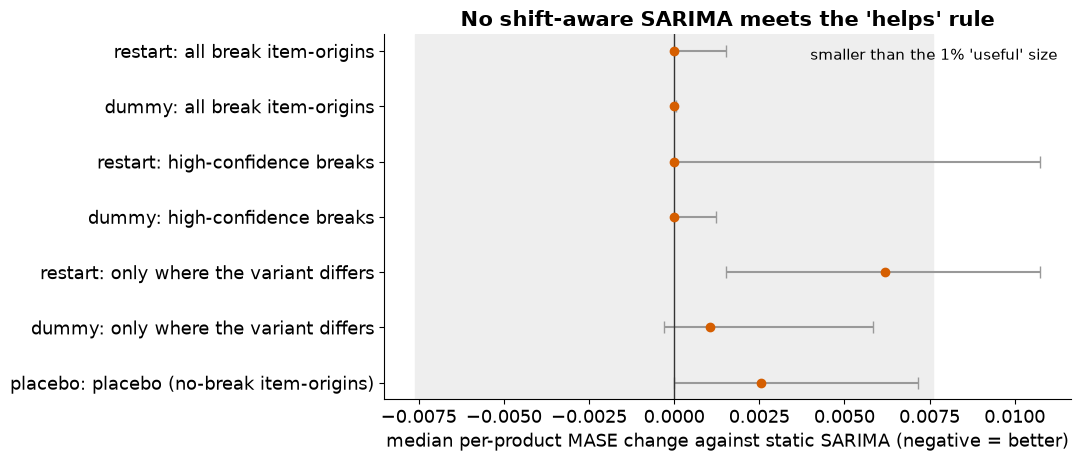

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.8))
t = tests.reset_index(drop=True)
labels = [f"{r.variant}: {r.group}" for r in t.itertuples()]
y = np.arange(len(t))[::-1]
ax.errorbar(t["median_diff"], y, xerr=[t["median_diff"] - t["ci_low"], t["ci_high"] - t["median_diff"]],
            fmt="o", color="#D55E00", ecolor="#999999", capsize=4)
ax.axvline(0, color="#333333", lw=1)
thr = t.loc[0, "practical_threshold"]
ax.axvspan(-thr, thr, color="#EEEEEE", zorder=0, label="smaller than the 1% 'useful' size")
ax.set_yticks(y, labels)
ax.set_xlabel("median per-product MASE change against static SARIMA (negative = better)")
ax.set_title("A shift-aware SARIMA meets the 'helps' rule" if helps_any else "No shift-aware SARIMA meets the 'helps' rule")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(FIGS / "shift_aware_sarima.png")
written.append(FIGS / "shift_aware_sarima.png")
plt.show()

In [7]:
# checks: every shift item-origin got both versions, placebo only where there was no shift,
# and only shifts dated before the origin were used
b = breaks[breaks["has_break"]]
assert len(sv[sv["variant"] == "restart"]) == len(b) == len(sv[sv["variant"] == "dummy"])
assert sv[sv["variant"] == "placebo"].merge(b, on=["item_id", "origin"]).empty
assert (b["last_change_week"] < b["origin"]).all()
print("fallbacks:", int(sv["fallback"].sum()), "of", int((~sv["same_as_static"]).sum()), "fitted versions")

fallbacks: 0 of 760 fitted versions


## What we found

Reacting to a detected shift did not help SARIMA. On all 449 shift item-origins in the sample neither version meets
our rule. For 44% of them the shift is older than the 730-day window, so the version is just the static model. Where
the version really differs (47 products), retraining from the shift is clearly worse, +0.0062 MASE (95% CI +0.0015
to +0.0107, Holm p = 0.002), and the shift marker is about neutral, +0.0010 (-0.0003 to +0.0058). The high-confidence
shifts tell the same story, and the SARIMA placebo is a little worse too (+0.0025).

So throwing away the history before a shift costs more than it gains. Our guess, which we have not tested, is that
SARIMA already follows a level change on its own, because it is refitted at every origin and weights recent weeks
more.

## What comes next

`09a_lightgbm` brings in machine learning, on exactly the same backtest, and tries the same retraining idea there.

In [8]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

data\processed\local_variant_forecasts.parquet 1,978 KB
outputs\tables\shift_aware_item_origin.csv 141 KB
outputs\tables\shift_aware_tests.csv 2 KB
outputs\figures\shift_aware_sarima.png 83 KB
